# Actividad en clase
## Ana Paula Moreno Haro
Simulación de trayectoria de caso estándar con secuencias de Sobol. Ejercicios de comparación contra Monte Carlo (integración y probabilidad).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import qmc, norm
import warnings
warnings.filterwarnings("ignore")   

## Ejercicio 1. Histogramas de U(0,1)
Instrucción: fijar `np.random.seed(20)`, generar muestras aleatorias de U(0,1) con n = 50, 100, 500, 1000 y 100000, y hacer el histograma de cada una.

1a. Números aleatorios (np.random)
1b. Proceso determinista (generador congruencial lineal)
Instrucción: repetir las mismas gráficas con un proceso determinista, X(n+1) = (a·Xn + b) mod m, normalizado dividiendo entre m.
1c. Secuencia de Sobol
Instrucción: repetir las mismas gráficas con `qmc.Sobol` (`from scipy.stats import qmc`).

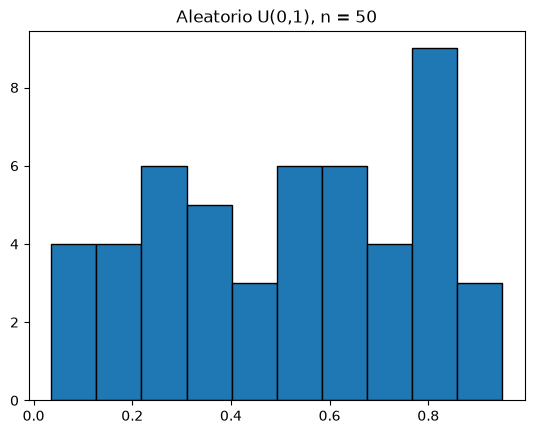

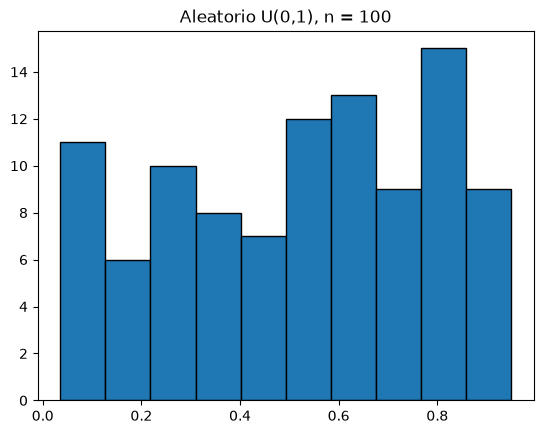

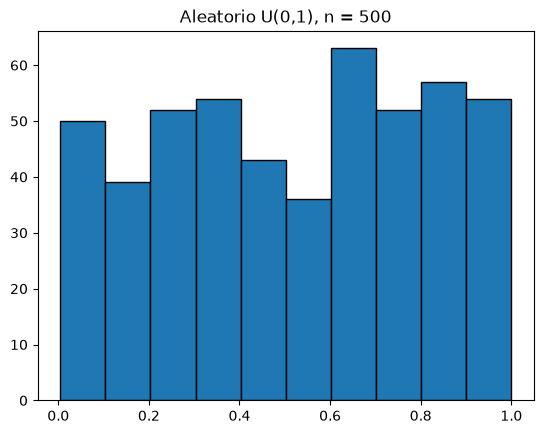

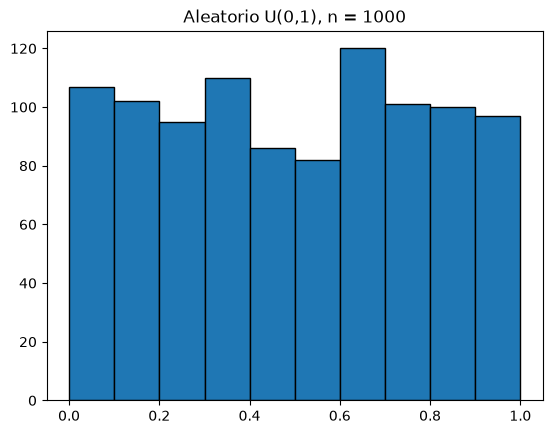

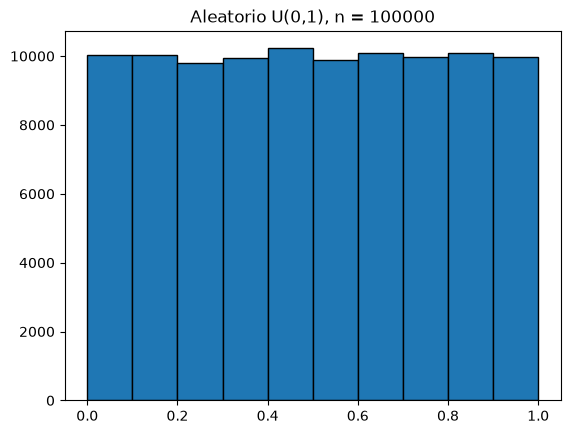

In [2]:
for n in [50, 100, 500, 1000, 100000]:
    np.random.seed(20)
    u = np.random.uniform(0, 1, n)
    plt.hist(u, bins=10, edgecolor="black")
    plt.title(f"Aleatorio U(0,1), n = {n}")
    plt.show()

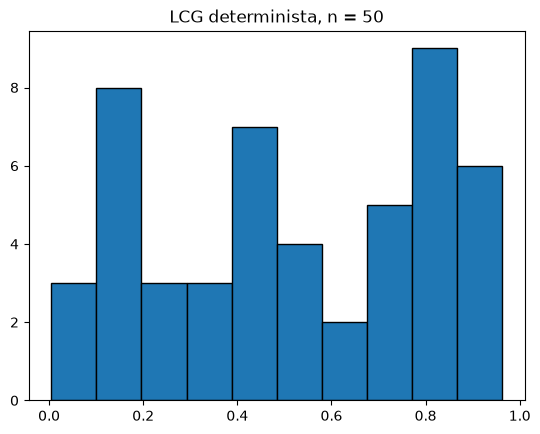

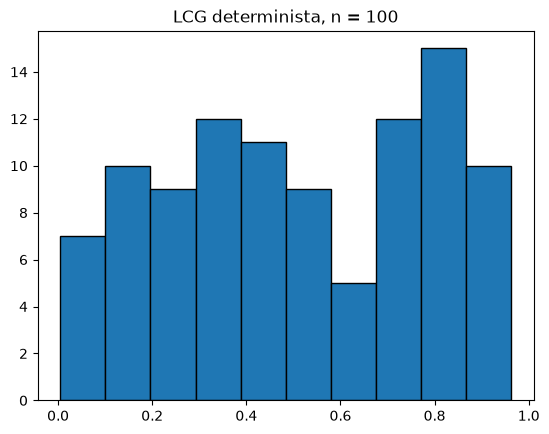

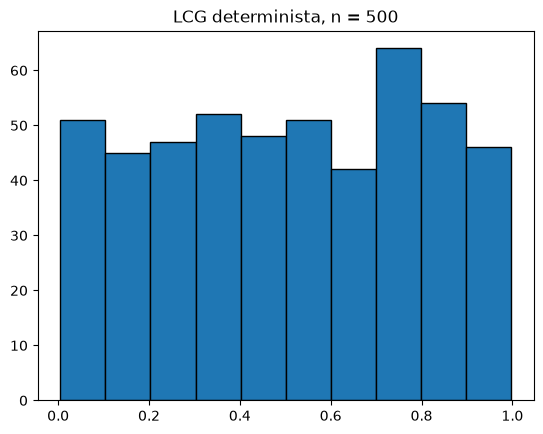

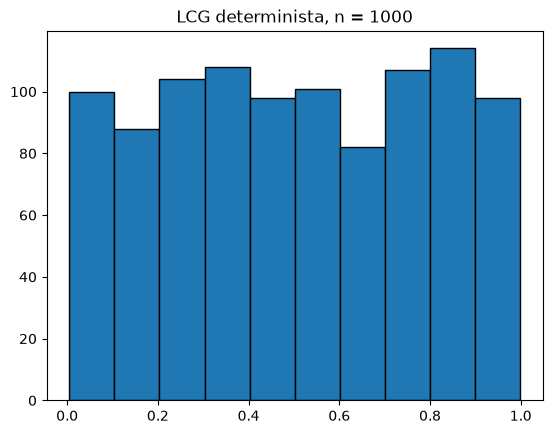

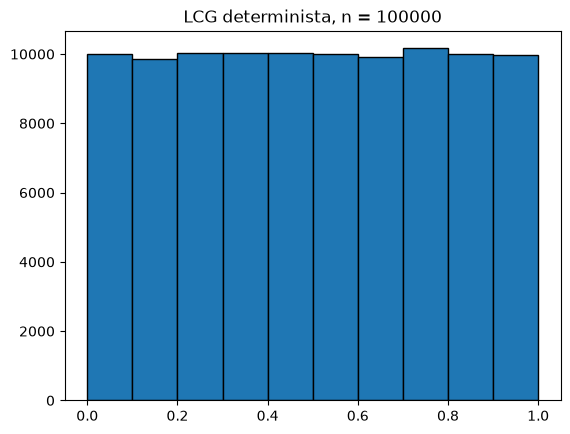

In [3]:
def gen(a, b, m, x0, n):
    x = x0
    lista = []
    for i in range(n):
        x = (a * x + b) % m
        lista.append(x / m)
    return np.array(lista)

a = 1103515245; b = 12345; m = 2**31 - 1; x0 = 744069

for n in [50, 100, 500, 1000, 100000]:
    u = gen(a, b, m, x0, n)
    plt.hist(u, bins=10, edgecolor="black")
    plt.title(f"LCG determinista, n = {n}")
    plt.show()

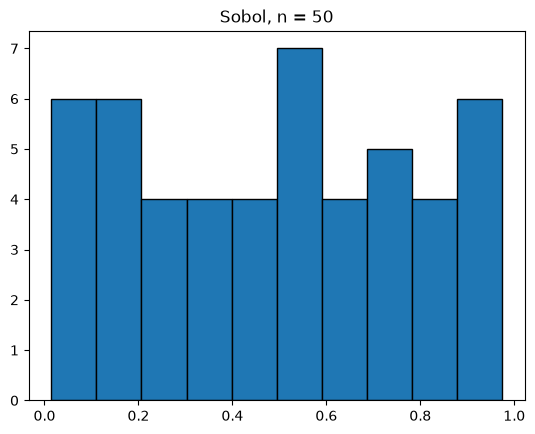

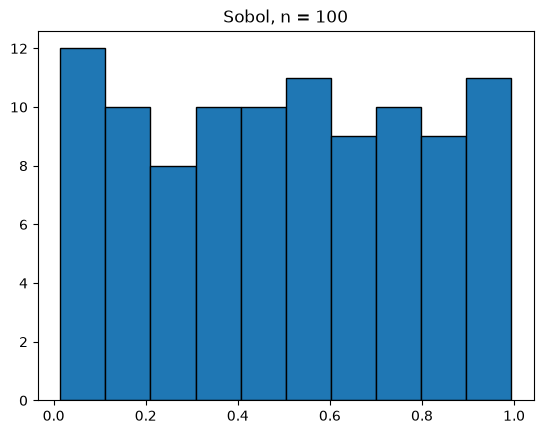

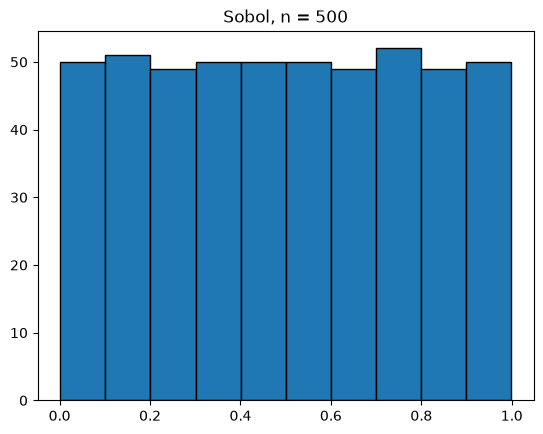

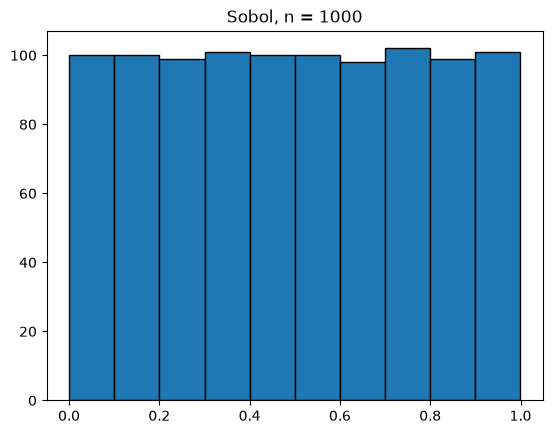

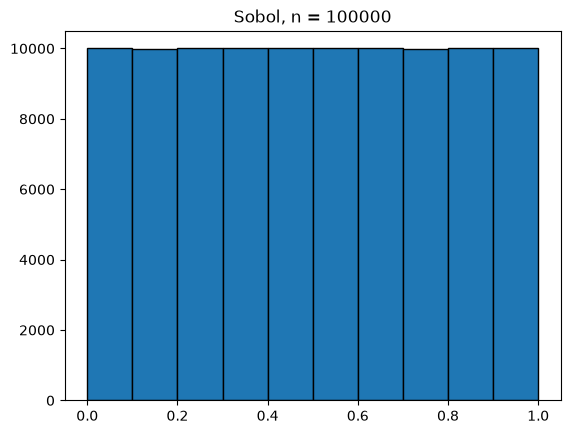

In [4]:
for n in [50, 100, 500, 1000, 100000]:
    sobol = qmc.Sobol(d=1, scramble=True, seed=20)
    u = sobol.random(n)
    plt.hist(u, bins=10, edgecolor="black")
    plt.title(f"Sobol, n = {n}")
    plt.show()

##### Ejercicio 2. Integración con Monte Carlo vs cuasi-Monte Carlo
Instrucción: aproximar ∫₀¹ x² dx (valor exacto = 1/3) con la fórmula ∫ₐᵇ f(x)dx = f(c)(b−a), donde f(c) se aproxima con el promedio de f evaluada en puntos de U(a,b).
Llenar la tabla para m = 100, 500, 1000 y 5000 con las columnas: m | f(c)(b−a) | error MC | error qmc.
Los puntos de qmc se generan con Sobol.

In [5]:
def f(x):
    return x**2

a = 0; b = 1; exacto = 1/3
filas = []
for m in [100, 500, 1000, 5000]:
    np.random.seed(20)
    x = np.random.uniform(a, b, m)
    est_mc = (b - a) * np.mean(f(x))

    sobol = qmc.Sobol(d=1, scramble=True, seed=20)
    xs = sobol.random(m)
    est_qmc = (b - a) * np.mean(f(xs))

    filas.append([m, est_mc, abs(est_mc - exacto), abs(est_qmc - exacto)])

tabla1 = pd.DataFrame(filas, columns=["m", "f(c)(b-a)", "error MC", "error qmc"])
display(tabla1)

,m,f(c)(b-a),error MC,error qmc
0,100,0.337295,0.003962,0.001264
1,500,0.354555,0.021221,0.000174
2,1000,0.333012,0.000321,0.000223
3,5000,0.338667,0.005334,0.000043


In [6]:
mu = 50; sigma = 10
filas = []
for m in [10, 100, 1000, 10000]:
    np.random.seed(20)
    u = np.random.uniform(0, 1, m)
    p_mc = np.mean(norm.ppf(u, mu, sigma) > 60)

    sobol = qmc.Sobol(d=1, scramble=True, seed=20)
    u = sobol.random(m)
    p_qmc = np.mean(norm.ppf(u, mu, sigma) > 60)

    filas.append([m, p_mc, p_qmc])

tabla2 = pd.DataFrame(filas, columns=["m", "MC", "qmc"])
display(tabla2)
print("Valor exacto:", 1 - norm.cdf(60, mu, sigma))   # 0.1587

,m,MC,qmc
0,10,0.2000,0.1000
1,100,0.1100,0.1600
2,1000,0.1580,0.1600
3,10000,0.1612,0.1585


Valor exacto: 0.15865525393145707


Black-Scholes: 6.0401
128 | MC: 7.5901 error: 1.55 | Sobol: 5.4725 error: 0.5676
512 | MC: 6.0519 error: 0.0118 | Sobol: 6.0261 error: 0.014
1024 | MC: 6.4863 error: 0.4462 | Sobol: 5.8643 error: 0.1758
4096 | MC: 6.5205 error: 0.4804 | Sobol: 6.0364 error: 0.0037


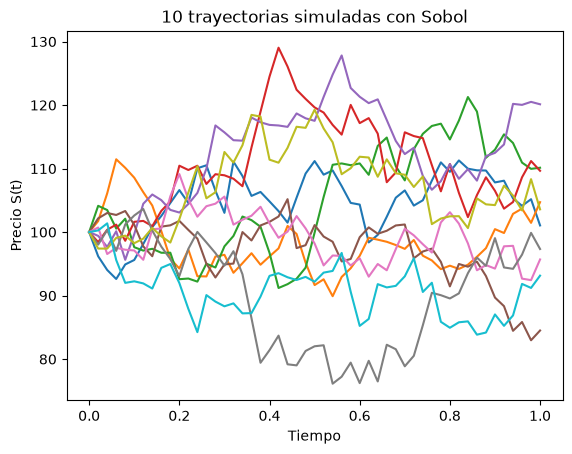

In [7]:
S0 = 100.0; r = 0.05; sigma = 0.20; T = 1.0; K = 110.0
pasos = 50
dt = T / pasos

def black_scholes_call(S0, K, r, sigma, T):
    d1 = (np.log(S0 / K) + (r + sigma**2 / 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

def trayectorias(Z):
    m = Z.shape[0]
    S = np.zeros((m, pasos + 1))
    S[:, 0] = S0
    for j in range(pasos):
        S[:, j+1] = S[:, j] * np.exp((r - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z[:, j])
    return S

precio_bs = black_scholes_call(S0, K, r, sigma, T)
print("Black-Scholes:", round(precio_bs, 4))

for m in [128, 512, 1024, 4096]:
    np.random.seed(20)
    Z_mc = np.random.normal(0, 1, (m, pasos))
    S_mc = trayectorias(Z_mc)
    p_mc = np.mean(np.exp(-r*T) * np.maximum(S_mc[:, -1] - K, 0))

    sobol = qmc.Sobol(d=pasos, scramble=True, seed=20)
    u = sobol.random(m)
    Z_q = norm.ppf(u)
    S_q = trayectorias(Z_q)
    p_q = np.mean(np.exp(-r*T) * np.maximum(S_q[:, -1] - K, 0))

    print(m, "| MC:", round(p_mc, 4), "error:", round(abs(p_mc - precio_bs), 4),
             "| Sobol:", round(p_q, 4), "error:", round(abs(p_q - precio_bs), 4))

t = np.linspace(0, T, pasos + 1)
plt.plot(t, S_q[:10].T)
plt.title("10 trayectorias simuladas con Sobol")
plt.xlabel("Tiempo"); plt.ylabel("Precio S(t)")
plt.show()

- Histogramas. Con pocos datos, las barras del aleatorio andan disparejas y se van acomodando conforme n crece, hasta verse planas con 100,000. El LCG se porta parecido, porque aunque es determinista “parece” aleatorio. Sobol queda parejo desde el inicio, porque está diseñado para llenar el intervalo de forma uniforme.

- Integración. El error de Monte Carlo es irregular, mientras que el de qmc es pequeño y baja casi siempre, hasta 0.00004 con m = 5000.

- Probabilidad. Con m = 10 los dos fallan, pero con m grande ambos se acercan al 15.87%. Sobol llega más estable (0.1585 con m = 10000).

- Trayectorias. Sobol se acerca más al precio de Black-Scholes (6.0401) y con m = 4096 casi lo clava (6.0364). Monte Carlo sigue oscilando (6.52). En m = 512 Monte Carlo ganó, pero fue suerte.

- Conclusión. Monte Carlo funciona porque, con muchos datos, el promedio converge, pero depende del azar y puede tardar. Los números cuasi-aleatorios de Sobol no son aleatorios, sino que están acomodados para cubrir bien el espacio, y por eso necesitan menos simulaciones para dar un resultado igual de bueno o mejor. Eso lo vimos en los histogramas, en la integral, en la probabilidad y en las trayectorias.

Los valores exactos pueden variar un poco si cambias semilla o corres otra vez, pero la tendencia debe ser la misma. Si quieres, lo armo ya como cuaderno con estas conclusiones en celdas de texto.